# CSC2042S Assignment 1: Unsupervised learning

## 1. Data Preprocessing
Loading the **WDI** dataset and preparing it for clustering.

In [1]:
import pandas as pd # TODO: Move all imports and constant defines to different cells for clarity
import numpy as np


# from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
# from sklearn.cluster import KMeans
from sklearn.manifold import TSNE

import matplotlib.pyplot as plt
# ensure plots display in notebook
%matplotlib inline

RANDOM_STATE: int = 42
WDI_CSV_PATH: str = 'WDICSV.csv'

pd.set_option('display.max_columns', 120)
rawDf = pd.read_csv(WDI_CSV_PATH)

yearCols = [c for c in rawDf.columns if c.isdigit()]
dataCols = ['Country Name','Country Code','Indicator Name','Indicator Code']

longDf = rawDf.melt(id_vars = dataCols, value_vars = yearCols, var_name = 'Year', value_name = 'Value')
longDf['Year'] = pd.to_numeric(longDf['Year'], errors = 'coerce').astype('Int64')
longDf['Value'] = pd.to_numeric(longDf['Value'], errors = 'coerce')

df = longDf.pivot_table(index=['Country Name','Country Code','Year'],
                       columns='Indicator Code',
                       values='Value',
                       aggfunc='mean').sort_index()
df.head()


Indicator Code                  AG.CON.FERT.PT.ZS  AG.CON.FERT.ZS  \
Country Name Country Code Year                                      
Afghanistan  AFG          1960                NaN             NaN   
                          1961                NaN        0.143791   
                          1962                NaN        0.142857   
                          1963                NaN        0.141935   
                          1964                NaN        0.141026   

Indicator Code                  AG.LND.AGRI.K2  AG.LND.AGRI.ZS  \
Country Name Country Code Year                                   
Afghanistan  AFG          1960             NaN             NaN   
                          1961        377500.0       57.878356   
                          1962        378000.0       57.955016   
                          1963        378500.0       58.031676   
                          1964        379050.0       58.116002   

Indicator Code                  AG.LND.ARBL.HA  AG.LND.ARBL.HA.PC  \
Country Name Country Code Year                                      
Afghanistan  AFG          1960             NaN                NaN   
                          1961       7650000.0           0.830251   
                          1962       7700000.0           0.818765   
                          1963       7750000.0           0.806915   
                          1964       7800000.0           0.794757   

Indicator Code                  AG.LND.ARBL.ZS  AG.LND.CREL.HA  \
Country Name Country Code Year                                   
Afghanistan  AFG          1960             NaN             NaN   
                          1961       11.728991       3313500.0   
                          1962       11.805651       3425500.0   
                          1963       11.882311       3426500.0   
                          1964       11.958972       3446500.0   

Indicator Code                  AG.LND.CROP.ZS  AG.LND.EL5M.RU.K2  \
Country Name Country Code Year                                      
Afghanistan  AFG          1960             NaN                NaN   
                          1961        0.153320                NaN   
                          1962        0.153320                NaN   
                          1963        0.153320                NaN   
                          1964        0.160986                NaN   

Indicator Code                  AG.LND.EL5M.RU.ZS  AG.LND.EL5M.UR.K2  \
Country Name Country Code Year                                         
Afghanistan  AFG          1960                NaN                NaN   
                          1961                NaN                NaN   
                          1962                NaN                NaN   
                          1963                NaN                NaN   
                          1964                NaN                NaN   

Indicator Code                  AG.LND.EL5M.UR.ZS  AG.LND.EL5M.ZS  \
Country Name Country Code Year                                      
Afghanistan  AFG          1960                NaN             NaN   
                          1961                NaN             NaN   
                          1962                NaN             NaN   
                          1963                NaN             NaN   
                          1964                NaN             NaN   

Indicator Code                  AG.LND.FRST.K2  AG.LND.FRST.ZS  \
Country Name Country Code Year                                   
Afghanistan  AFG          1960             NaN             NaN   
                          1961             NaN             NaN   
                          1962             NaN             NaN   
                          1963             NaN             NaN   
                          1964             NaN             NaN   

Indicator Code                  AG.LND.IRIG.AG.ZS  AG.LND.PRCP.MM  \
Country Name Country Code Year                                      
Afghanistan  AFG          1960  

### Filtering the data to remove some nulls
TODO: Actually document this properly, cos rn idk what the heck is going on here

In [2]:
from typing import Any

ROW_THRESH: float = 0.7
FEAT_THRESH: float = 0.7  # Adjust thresholds as needed

def ProcessMissing(df) -> dict[str, Any]:
    total = df.size
    missing = df.isna().sum().sum()
    return {
        'rows': df.shape[0],
        'features': df.shape[1],
        'missing_pct': float(missing/total) if total > 0 else np.nan
    }

filtered = df.copy()
featCov = filtered.notna().mean(axis=0)
filtered = filtered.loc[:, featCov >= FEAT_THRESH]
rowCov = filtered.notna().mean(axis=1)
filtered = filtered.loc[rowCov >= ROW_THRESH]
ProcessMissing(filtered)

{'rows': 14550, 'features': 178, 'missing_pct': 0.06333101664156918}

### Impute missing values (whatever that means)

In [3]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="mean")

x = imputer.fit_transform(filtered.iloc[:, 5:])  # assuming first cols are metadata
print(x)

[[ 3.44650000e+06  1.60986155e-01  6.52230000e+05 ...  0.00000000e+00
   3.88000000e+07  4.56185567e+01]
 [ 3.44450000e+06  1.68652163e-01  6.52230000e+05 ...  0.00000000e+00
   4.34000000e+07  3.34101382e+01]
 [ 3.12450000e+06  2.06982200e-01  6.52230000e+05 ... -4.47192247e-15
   4.16520000e+07  3.91697878e+01]
 ...
 [ 1.32235100e+06  1.54711128e-01  3.86850000e+05 ...  0.00000000e+00
   5.82002438e+09  6.12026428e+01]
 [ 1.33724400e+06  1.52961096e-01  3.86850000e+05 ...  0.00000000e+00
   6.43744721e+09  4.91674259e+01]
 [ 3.18072643e+07  3.65981800e+00  5.27189884e+06 ...  0.00000000e+00
   6.94147328e+09  4.16992671e+01]]


### Scale everything zero to one

In [4]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
xScaled = scaler.fit_transform(x)
print(xScaled)

[[4.65953774e-03 2.41479233e-03 5.01880495e-03 ... 3.01696799e-14
  1.62201072e-06 4.61372884e-01]
 [4.65683381e-03 2.52978244e-03 5.01880495e-03 ... 3.01696799e-14
  1.81435006e-06 3.37900425e-01]
 [4.22420591e-03 3.10473299e-03 5.01880495e-03 ... 3.00273357e-14
  1.74126111e-06 3.96151876e-01]
 ...
 [1.78776857e-03 2.32066693e-03 2.97671722e-03 ... 3.01696799e-14
  2.43351764e-04 6.18985882e-01]
 [1.80790335e-03 2.29441644e-03 2.97671722e-03 ... 3.01696799e-14
  2.69168003e-04 4.97265134e-01]
 [4.30022192e-02 5.48972700e-02 4.05669587e-02 ... 3.01696799e-14
  2.90242794e-04 4.21734308e-01]]


### Dimensionality reduction for visualization

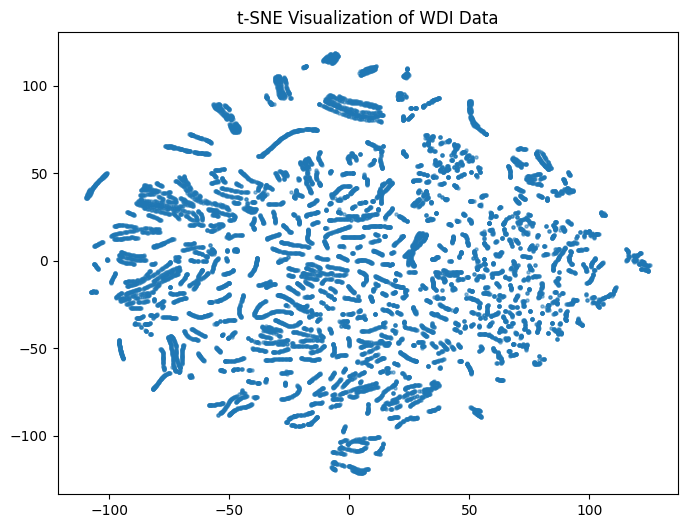

In [5]:
xEmbedded = TSNE(n_components=2, random_state=42).fit_transform(xScaled)

plt.figure(figsize=(8,6))
plt.scatter(xEmbedded[:,0], xEmbedded[:,1], s = 5, alpha = 0.5) # What the heck is [:,1] syntax in Python
plt.title("t-SNE Visualization of WDI Data")
plt.show()

### K-Means Clustering

In [7]:
import numpy as np

def EuclideanDistance(a, b):
    return np.linalg.norm(a - b) # a and b should be vectors here

def InitializeCentroids(x, k):
    indices = np.random.choice(x.shape[0], k, replace = False)
    return x[indices]

def AssignClusters(x, centroids):
    clusters = []
    for myX in x:
        distances = [EuclideanDistance(myX, c) for c in centroids]
        clusterIndex = np.argmin(distances) # Find the index of the shortest distance
        clusters.append(clusterIndex)
        
    return np.array(clusters)

def UpdateCentroids(x, clusters, k):
    centroids = []
    for i in range(k):
        points = x[clusters == i] # What the heck is going on here with the '=='
        if len(points) > 0:
            centroids.append(points.mean(axis = 0))
        else:
            centroids.append(x[np.random.randint(0, x.shape[0])])

    return np.array(centroids)

def KMeans(x, k, maxIters = 100, tol = 1e-4):
    centroids = InitializeCentroids(x, k)
    
    for _ in range(maxIters):
        clusters = AssignClusters(x, centroids)
        newCentroids = UpdateCentroids(x, clusters, k)
        
        if np.all(np.abs(newCentroids - centroids) < tol):
            break
        
        centroids = newCentroids
    
    return clusters, centroids

### Performing the clustering and visualization

Cluster assignments: [12 12 12 ... 10 10 10]
Centroids: [[0.02372918 0.04557522 0.01318319 ... 0.02492609 0.00589367 0.20214831]
 [0.01463173 0.07422646 0.0174395  ... 0.01946813 0.0019109  0.13248476]
 [0.02073435 0.15079959 0.00769043 ... 0.00449859 0.00225334 0.10197773]
 ...
 [0.35970364 0.02180503 0.31674129 ... 0.00873725 0.01623978 0.08716608]
 [0.71033954 0.02315141 0.67584982 ... 0.00977549 0.22244121 0.10858229]
 [0.08691087 0.014775   0.1002032  ... 0.00221333 0.0013443  0.09094373]]


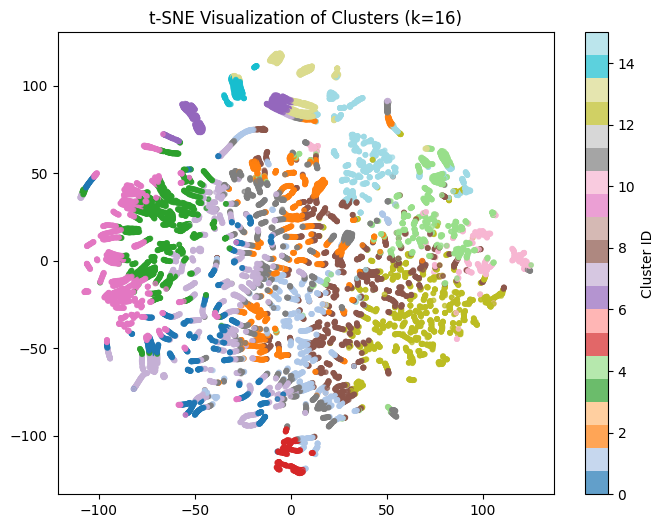

In [8]:
k = 16 # TODO: We need to find the optimal k using the elbow & silhouette method
clusters, centroids = KMeans(xScaled, k)

print("Cluster assignments:", clusters)
print("Centroids:", centroids)

# Plot
plt.figure(figsize=(8,6))
plt.scatter(
    xEmbedded[:,0],   # x-axis
    xEmbedded[:,1],   # y-axis
    c=clusters,       # color by cluster
    cmap="tab20",     # 20 distinct colors (works well since k=16)
    s=10,             # point size
    alpha=0.7         # transparency
)
plt.title(f"t-SNE Visualization of Clusters (k={k})")
plt.colorbar(label = "Cluster ID")
plt.show()